In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

required_files = [
    "data/processed/train.csv",
    "data/processed/validation.csv",
    "data/processed/test.csv",
    "data/reports/step3_ann_metrics.csv",
    "data/reports/step4_baseline_metrics.csv",
    "data/reports/step4_comparison.csv",
    "results/step4_baseline_vs_ann.png"
]

for file in required_files:
    path = Path(file)
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {file}")

MISSING: data/processed/train.csv
MISSING: data/processed/validation.csv
MISSING: data/processed/test.csv
MISSING: data/reports/step3_ann_metrics.csv
MISSING: data/reports/step4_baseline_metrics.csv
MISSING: data/reports/step4_comparison.csv
MISSING: results/step4_baseline_vs_ann.png


In [2]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)

Current folder:
c:\Users\devas\Downloads\Academic-Intervention-System-main\Academic-Intervention-System-main\notebooks

Files and folders here:
.04_baseline_comparison.ipynb
01_data_inspection.ipynb
02_ann_model.ipynb
03_perceptron_adaline.ipynb


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("\nRequired folders:")

for folder in ["data", "results", "src", "docs", "notebooks"]:
    path = PROJECT_ROOT / folder
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {folder}")

Project root: c:\Users\devas\Downloads\Academic-Intervention-System-main\Academic-Intervention-System-main

Required folders:
FOUND: data
FOUND: results
FOUND: src
FOUND: docs
FOUND: notebooks


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent

metrics_path = PROJECT_ROOT / "data" / "reports" / "step4_baseline_metrics.csv"
comparison_path = PROJECT_ROOT / "data" / "reports" / "step4_comparison.csv"
plot_path = PROJECT_ROOT / "results" / "step4_baseline_vs_ann.png"

print("Baseline metrics file:", metrics_path.exists())
print("Comparison file:", comparison_path.exists())
print("Comparison graph:", plot_path.exists())

if metrics_path.exists() and comparison_path.exists():
    baseline_metrics = pd.read_csv(metrics_path)
    comparison = pd.read_csv(comparison_path)

    print("\nBaseline metrics:")
    display(baseline_metrics)

    print("\nBaseline vs ANN comparison:")
    display(comparison)
else:
    print("\nOne or more files are missing. Please share this output.")

Baseline metrics file: True
Comparison file: True
Comparison graph: True

Baseline metrics:


,Split,Model,Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives
0,validation,Threshold Baseline,0.720802,0.917010,0.518016,0.662045,121,1244
1,validation,ANN,0.828186,0.866526,0.797365,0.830508,317,523
2,test,Threshold Baseline,0.723052,0.916497,0.523053,0.666009,123,1231
3,test,ANN,0.837390,0.874895,0.807439,0.839815,298,497



Baseline vs ANN comparison:


,Split,Baseline Threshold,Baseline Accuracy,ANN Accuracy,Baseline Precision,ANN Precision,Baseline Recall,ANN Recall,Baseline F1 Score,ANN F1 Score,Baseline False Positives,ANN False Positives,Baseline False Negatives,ANN False Negatives
0,validation,50.0,0.720802,0.828186,0.917010,0.866526,0.518016,0.797365,0.662045,0.830508,121,317,1244,523
1,test,50.0,0.723052,0.837390,0.916497,0.874895,0.523053,0.807439,0.666009,0.839815,123,298,1231,497


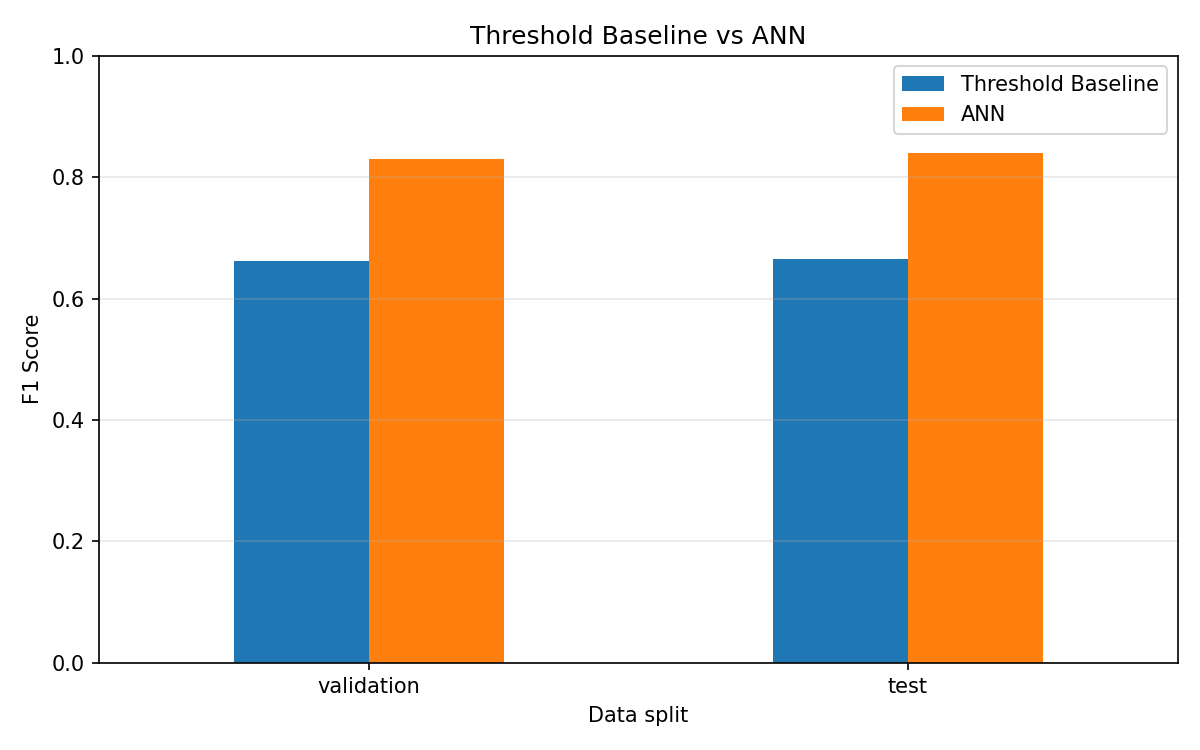

In [5]:
from pathlib import Path
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd().parent
plot_path = PROJECT_ROOT / "results" / "step4_baseline_vs_ann.png"

if plot_path.exists():
    display(Image(filename=str(plot_path)))
else:
    print("Graph not found:", plot_path)

# Step 4: Baseline Comparison

## Objective
The objective of this experiment is to compare a simple assessment-based threshold baseline with the trained Artificial Neural Network (ANN).

## Baseline Method
The baseline predicts a student as at-risk when `assessment_average` is less than or equal to 50. Otherwise, it predicts the student as not at-risk. The threshold is fixed and is not tuned using validation or test outcomes.

## Results and Observations
- The ANN achieved higher accuracy, recall, and F1 score than the baseline on both validation and test datasets.
- The baseline achieved higher precision, but it missed more at-risk students.
- On the test dataset, the baseline produced 1,231 false negatives, while the ANN produced 497.
- The results suggest that the ANN identifies more at-risk students than this simple threshold rule.

## Conclusion
The ANN performed better overall than the threshold baseline on the evaluated datasets. However, the results alone do not establish fairness or guarantee performance in real-world settings.

The system should be used as a decision-support tool to help educators identify students who may benefit from additional academic support. It should not be used for automatic punishment or high-stakes decisions.

## Limitations
The baseline considers only assessment average. The current experiment is not a complete fairness audit, and further evaluation across relevant student groups is required before real-world deployment.